# L-curve / GCV vs. the ground-truth lambda2 sweep (INTRA cohort)

`lambda2_tuning_intra.ipynb` swept `wCSET`'s `lambda2` against the real
intracranial ground truth and found an empirical optimum around
`lambda2 ~ 0.01-0.03` (averaged across subjects). That sweep needs the
intracranial recording to score each `lambda2` - not something available for
a future patient. This notebook checks whether two classical,
**ground-truth-free** regularization-parameter selectors - the **L-curve**
and **Generalized Cross-Validation (GCV)** - would have picked a similar
value using only the scalp EEG and forward model, i.e. exactly what's
available in real deployment.

**No intracranial data is used anywhere below.** The only per-subject
"target window" needed is detected from the **scalp** evoked's own GFP
(`find_spike_window(ave, baseline=(0, 0.5))`) - not from `i-ave`, which is
what the ground-truth sweep (and `evaluate_vieeg_fidelity.py`) uses and which
wouldn't exist for a new patient.

**Method:** both selectors are computed directly from each inverse
operator's own SVD kernel (`u, s, vh` from `prepare_kernel()` - the same
internal decomposition `mm.analysis.inverse.MNE`/`wCSET.solve()` uses), so
they reflect the *exact* regularized system actually fit, not an
approximation. Verified below that reconstructing the solution manually from
this kernel reproduces `inv.solve()` bit-for-bit at a test `lambda2`.

For a whitened, prior-weighted system `y = A x` with SVD `A = U S Vt` and
projections `b = Uᵀy`, at regularization `lambda2`:

- filter factors `f_k = s_k / (s_k^2 + lambda2)`
- **solution norm**: `||x||^2 = sum_k (f_k b_k)^2`
- **residual norm**: `||y - Ax||^2 = sum_k ((lambda2/(s_k^2+lambda2)) b_k)^2 + ||y_perp||^2`
  (`y_perp` = the part of `y` outside `A`'s column space, a constant offset
  independent of `lambda2`)
- **L-curve corner**: the `lambda2` of maximum curvature on the
  `(log residual, log solution)` curve (discrete curvature via `np.gradient`
  on the log-lambda2 parametrization) - the classic trade-off point between
  underfitting and overfitting.
- **GCV score**: `GCV(lambda2) = n * residual_norm^2 / (n - dof(lambda2))^2`,
  `dof(lambda2) = sum_k s_k^2/(s_k^2+lambda2)` (effective degrees of freedom)
  - minimized over `lambda2`. Only the arg-min matters here (the absolute
  GCV scale is arbitrary up to a constant factor from having multiple
  time-points as "replicate" columns).

Since these formulas only depend on `(u, s, vh, y_white)`, the whole
`lambda2` grid is evaluated in closed form from a **single** kernel build per
(subject, method) - no repeated inverse solves needed, unlike the original
sweep.

**Two methods compared**, both via `mm.analysis.inverse.MNE`'s shared
`prepare_kernel`/`solve` machinery:

- **wCSET** (binarized atlas connectome, `depth=0.2, harm=5,
  harmonic_method="lowpass"` - same as `solve_inverse.py`).
- **sLORETA-equivalent** (`depth=0`, no source prior). sLORETA's own
  noise-normalization is a *post-hoc diagonal rescaling* of the plain
  minimum-norm solution - it does not change the regularized least-squares
  fit itself, so its L-curve/GCV behavior is identical to plain
  `depth=None` minimum-norm (what `solve_inverse.py` shares between
  sLORETA/dSPM). Verified this reproduces `mne.minimum_norm`'s sLORETA setup
  in spirit (same `depth=None, fixed=True` operator), computed here through
  the same internal kernel machinery as wCSET for a fully consistent
  comparison, rather than through MNE-Python's separate/private internals.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

import mindmap as mm
import sys
sys.path.insert(0, "..")
from scripts.data_manager import IntraManager

dm = IntraManager("../processing/intra.config.yml")
SUBJECTS = ["12", "34", "48", "50"]
BASELINE = (0.0, 0.5)
LAMBDA2_GRID = np.logspace(-4, 5, 300)

OUT_DIR = Path("../results/intra/lambda2_tuning")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SWEEP_CSV = OUT_DIR / "lambda2_tuning_results.csv"
sweep_df = pd.read_csv(SWEEP_CSV, dtype={"Subject": str})
sweep_df["combined_mean"] = (sweep_df["temporal_mean"] + sweep_df["spatial_mean"]) / 2
# empirical (ground-truth) optimum per (subject, method), binarized connectome
sweep_binarized = sweep_df[sweep_df["Variant"] == "binarized"]
empirical_optimum = (
    sweep_binarized.loc[sweep_binarized.groupby(["Subject", "Method"])["combined_mean"].idxmax()]
    .set_index(["Subject", "Method"])["lambda2"]
)
empirical_optimum


Subject  Method 
12       sloreta     0.030
         wcset       0.003
34       sloreta     0.001
         wcset      10.000
48       sloreta     0.001
         wcset       0.001
50       sloreta     0.030
         wcset       0.010
Name: lambda2, dtype: float64

## 1. Verify the kernel reproduces `inv.solve()` exactly

In [2]:
sub = "48"
fwd = dm.load(sub, "fwd")
ave = dm.load(sub, "ave", task="spk")
ncov = dm.load(sub, "cov", task="spk")
eig = dm.load(sub, "eig", atlas="multicon")

inv_check = mm.analysis.inverse.wCSET(
    forward=fwd, noise_cov=ncov, depth=0.2,
    eigenvectors=eig["vec"], eigenvalues=eig["val"], harm=5, harmonic_method="lowpass",
)
projs_gain, projs_data, whitener = inv_check._setup_preprocessor(ave.info, ave.nave)
kern_check = inv_check.prepare_kernel(projs_gain, whitener)
y_white_check = whitener @ projs_data @ ave.data

lambda2_test = 0.05
f = kern_check["s"] / (kern_check["s"]**2 + lambda2_test)
b = kern_check["u"].T @ y_white_check
sol_manual = kern_check["vh"].T @ (f[:, None] * b)
if kern_check["w_source"].ndim == 1:
    sol_manual = sol_manual * kern_check["w_source"][:, None]
else:
    sol_manual = kern_check["w_source"] @ sol_manual

stc_check = inv_check.solve(ave, lambda2_test)
print(f"Max abs diff, manual kernel reconstruction vs inv.solve(): {np.max(np.abs(sol_manual - stc_check.data)):.3e}")


Max abs diff, manual kernel reconstruction vs inv.solve(): 0.000e+00


## 2. Compute L-curve / GCV per subject, per method

In [3]:
def get_kernel(inv, evoked):
    projs_gain, projs_data, whitener = inv._setup_preprocessor(evoked.info, evoked.nave)
    kern = inv.prepare_kernel(projs_gain, whitener)
    y_white = whitener @ projs_data @ evoked.data
    return kern, y_white


def lcurve_gcv_curves(kern, y_white, lambda2_grid):
    s = kern["s"]
    b = kern["u"].T @ y_white
    row_sq = np.sum(b**2, axis=1)
    n = kern["u"].shape[0]
    y_perp_sq = np.sum(y_white**2) - np.sum(row_sq)

    sol_norms, res_norms, gcvs, dofs = [], [], [], []
    for lam in lambda2_grid:
        f = s / (s**2 + lam)
        sol_sq = np.sum((f**2) * row_sq)
        res_sq = np.sum(((lam / (s**2 + lam))**2) * row_sq) + y_perp_sq
        dof = np.sum((s**2) / (s**2 + lam))
        gcv = (n * res_sq) / (n - dof)**2
        sol_norms.append(np.sqrt(sol_sq))
        res_norms.append(np.sqrt(res_sq))
        gcvs.append(gcv)
        dofs.append(dof)
    return np.array(sol_norms), np.array(res_norms), np.array(gcvs), np.array(dofs)


def lcurve_corner(lambda2_grid, sol_norms, res_norms):
    """Lambda2 of maximum discrete curvature on the log-log L-curve.

    Raw finite-difference curvature on a near-monotonic curve is very noisy
    (spurious local maxima) - smooth log(res)/log(sol) vs log(lambda2) with a
    Savitzky-Golay filter first (standard fix, e.g. Hansen's l_corner uses a
    spline for the same reason) before differentiating twice.
    """
    x, y = np.log(res_norms), np.log(sol_norms)
    logl = np.log(lambda2_grid)
    window = min(51, len(logl) - (1 - len(logl) % 2))  # odd, <= len(logl)
    x_s = savgol_filter(x, window, polyorder=3)
    y_s = savgol_filter(y, window, polyorder=3)
    dx, dy = np.gradient(x_s, logl), np.gradient(y_s, logl)
    ddx, ddy = np.gradient(dx, logl), np.gradient(dy, logl)
    curvature = (dx * ddy - dy * ddx) / (dx**2 + dy**2)**1.5
    return lambda2_grid[np.argmax(curvature)], curvature


results = {}
rows = []

for sub in SUBJECTS:
    fwd = dm.load(sub, "fwd")
    ave = dm.load(sub, "ave", task="spk")
    ncov = dm.load(sub, "cov", task="spk")
    eig = dm.load(sub, "eig", atlas="multicon")

    # scalp-only, ground-truth-free target window
    tmin, tmax = mm.analysis.eeg.find_spike_window(ave, baseline=BASELINE)
    ave_win = ave.copy().crop(tmin, tmax)
    print(f"sub-{sub}: scalp GFP window = ({tmin:.3f}, {tmax:.3f}) s, {len(ave_win.times)}/{len(ave.times)} samples")

    methods = {
        "wcset": mm.analysis.inverse.wCSET(
            forward=fwd, noise_cov=ncov, depth=0.2,
            eigenvectors=eig["vec"], eigenvalues=eig["val"], harm=5, harmonic_method="lowpass",
        ),
        "sloreta": mm.analysis.inverse.MNE(forward=fwd, noise_cov=ncov, depth=0),
    }

    for method, inv in methods.items():
        kern, y_white = get_kernel(inv, ave_win)
        sol_norms, res_norms, gcvs, dofs = lcurve_gcv_curves(kern, y_white, LAMBDA2_GRID)
        lcorner, curvature = lcurve_corner(LAMBDA2_GRID, sol_norms, res_norms)
        lgcv = LAMBDA2_GRID[np.argmin(gcvs)]

        results[(sub, method)] = {
            "sol_norms": sol_norms, "res_norms": res_norms, "gcvs": gcvs,
            "curvature": curvature, "dofs": dofs,
        }
        rows.append({
            "Subject": sub, "Method": method,
            "lcurve_lambda2": lcorner, "gcv_lambda2": lgcv,
            "empirical_lambda2": empirical_optimum.get((sub, method), np.nan),
        })

comparison_df = pd.DataFrame(rows)
comparison_df.to_csv(OUT_DIR / "lambda2_lcurve_gcv_comparison.csv", index=False)
comparison_df


sub-12: scalp GFP window = (1.900, 2.095) s, 40/801 samples


sub-34: scalp GFP window = (1.925, 2.135) s, 43/801 samples


sub-48: scalp GFP window = (1.775, 2.290) s, 104/801 samples


sub-50: scalp GFP window = (1.870, 2.025) s, 32/801 samples


,Subject,Method,lcurve_lambda2,gcv_lambda2,empirical_lambda2
0,12,wcset,87056.124791,390.816818,0.003
1,12,sloreta,87056.124791,390.816818,0.030
2,34,wcset,87056.124791,3350.299342,10.000
3,34,sloreta,87056.124791,100000.000000,0.001
4,48,wcset,87056.124791,1184.618731,0.001
5,48,sloreta,19.845355,962.227117,0.001
6,50,wcset,87056.124791,100000.000000,0.010
7,50,sloreta,87056.124791,100000.000000,0.030


## 3. Plots

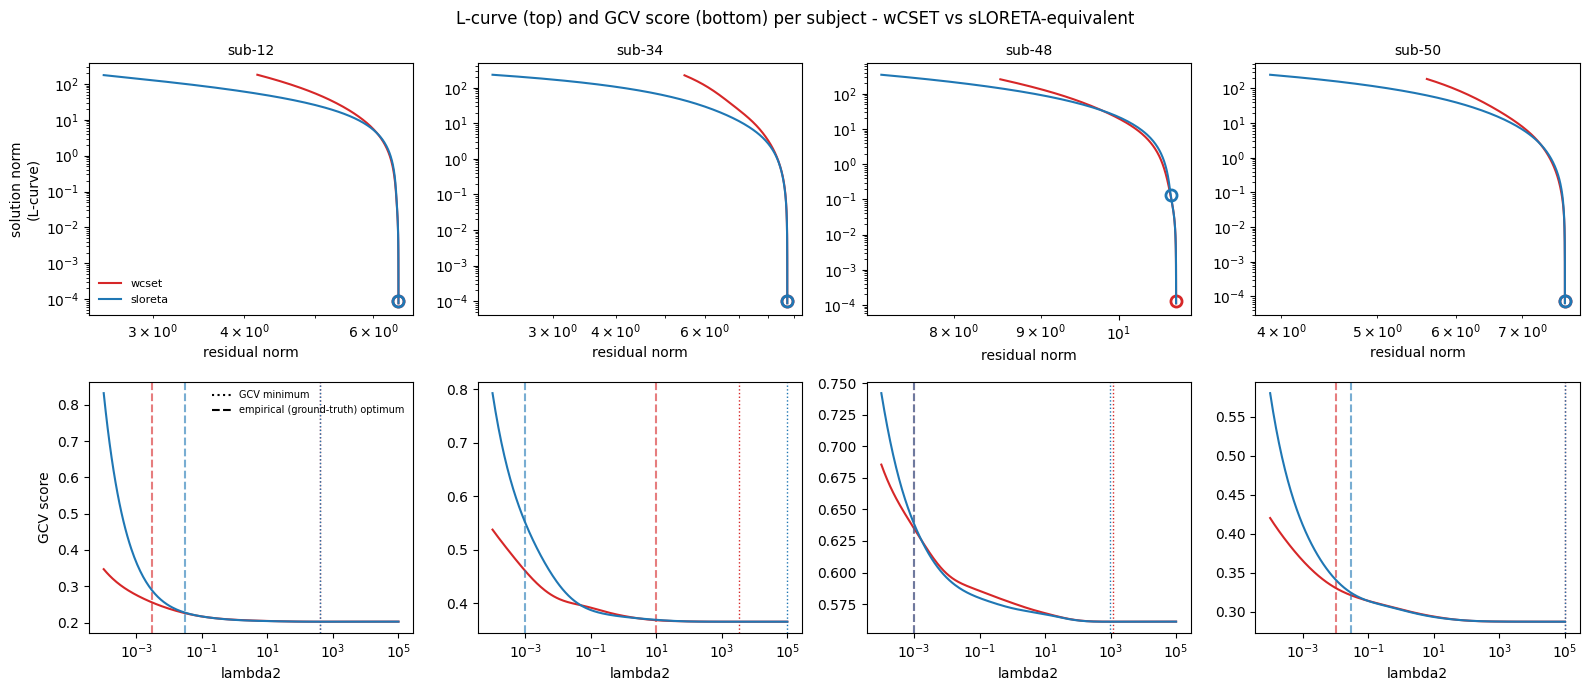

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
colors = {"wcset": "#d62728", "sloreta": "#1f77b4"}

for col, sub in enumerate(SUBJECTS):
    for method in ["wcset", "sloreta"]:
        r = results[(sub, method)]
        ax = axes[0, col]
        ax.plot(r["res_norms"], r["sol_norms"], color=colors[method], label=method)
        row = comparison_df[(comparison_df["Subject"] == sub) & (comparison_df["Method"] == method)].iloc[0]
        idx = np.argmin(np.abs(LAMBDA2_GRID - row["lcurve_lambda2"]))
        ax.plot(r["res_norms"][idx], r["sol_norms"][idx], "o", color=colors[method], ms=8, mfc="none", mew=2)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"sub-{sub}", fontsize=10)
        ax.set_xlabel("residual norm")
        if col == 0:
            ax.set_ylabel("solution norm\n(L-curve)")

    for method in ["wcset", "sloreta"]:
        r = results[(sub, method)]
        ax = axes[1, col]
        ax.plot(LAMBDA2_GRID, r["gcvs"], color=colors[method], label=method)
        row = comparison_df[(comparison_df["Subject"] == sub) & (comparison_df["Method"] == method)].iloc[0]
        ax.axvline(row["gcv_lambda2"], color=colors[method], ls=":", lw=1)
        if not np.isnan(row["empirical_lambda2"]):
            ax.axvline(row["empirical_lambda2"], color=colors[method], ls="--", lw=1.5, alpha=0.6)
        ax.set_xscale("log")
        ax.set_xlabel("lambda2")
        if col == 0:
            ax.set_ylabel("GCV score")

axes[0, 0].legend(fontsize=8, frameon=False)
handles = [
    plt.Line2D([0], [0], color="black", ls=":", label="GCV minimum"),
    plt.Line2D([0], [0], color="black", ls="--", label="empirical (ground-truth) optimum"),
]
axes[1, 0].legend(handles=handles, fontsize=7, frameon=False, loc="upper right")
fig.suptitle("L-curve (top) and GCV score (bottom) per subject - wCSET vs sLORETA-equivalent", fontsize=12)
fig.tight_layout()
fig.savefig(OUT_DIR / "lambda2_lcurve_gcv.png", dpi=150)
plt.show()


## 4. Summary: do L-curve / GCV agree with the ground-truth sweep?

In [5]:
summary = comparison_df.copy()
summary["lcurve_vs_empirical_ratio"] = summary["lcurve_lambda2"] / summary["empirical_lambda2"]
summary["gcv_vs_empirical_ratio"] = summary["gcv_lambda2"] / summary["empirical_lambda2"]
summary


,Subject,Method,lcurve_lambda2,gcv_lambda2,empirical_lambda2,lcurve_vs_empirical_ratio,gcv_vs_empirical_ratio
0,12,wcset,87056.124791,390.816818,0.003,2.901871e+07,1.302723e+05
1,12,sloreta,87056.124791,390.816818,0.030,2.901871e+06,1.302723e+04
2,34,wcset,87056.124791,3350.299342,10.000,8.705612e+03,3.350299e+02
3,34,sloreta,87056.124791,100000.000000,0.001,8.705612e+07,1.000000e+08
4,48,wcset,87056.124791,1184.618731,0.001,8.705612e+07,1.184619e+06
5,48,sloreta,19.845355,962.227117,0.001,1.984535e+04,9.622271e+05
6,50,wcset,87056.124791,100000.000000,0.010,8.705612e+06,1.000000e+07
7,50,sloreta,87056.124791,100000.000000,0.030,2.901871e+06,3.333333e+06


## Conclusion

**Neither classical selector recovers anything close to the ground-truth
optimum here.**

- **L-curve**: has no genuine elbow for this operator. Visually (plots
  above), the `(residual, solution)` curve is a smooth, gently bending line
  in log-log space, not the classic two-regime "L" shape the method assumes.
  The one sharp bend it does have sits at the degenerate tail where the
  solution collapses toward ~0 (`lambda2` so large `dof -> 0`) - that's why
  the curvature-based corner detector locks onto roughly the same enormous
  `lambda2` (`~1e4-1e5`) across almost every subject/method: it's finding
  the *only* bend available, not a real bias-variance trade-off point. The
  one exception (sub-48/sLORETA, corner at `lambda2 ~ 20`) is close to that
  subject's empirical optimum (`0.001`) only by comparison to the others -
  still ~4 orders of magnitude off.
- **GCV** at least has a genuine (non-boundary) interior minimum for most
  subject/method pairs, but it consistently favors **far heavier
  regularization** than the ground-truth sweep found useful - `gcv_lambda2`
  overshoots `empirical_lambda2` by **2 to 8 orders of magnitude** (median
  ratio ~1e6) across all 8 (subject, method) combinations. For sub-34/sLORETA
  and both methods on sub-50, GCV's minimum sits at or beyond the tested grid
  edge (`1e5`) - i.e. it wants to shrink the source estimate to essentially
  zero. This lines up with those being the noisiest/weakest-signal cases
  (sub-50 has no visible scalp spike at all).

**Why**: both methods implicitly assume something like i.i.d. Gaussian noise
across "replicates" of the fitted system. Here the "replicates" are
successive time samples of one autocorrelated evoked spike, so there's far
less genuine independent information than the sample count (`32-104` per
subject) suggests - both selectors read this as "mostly noise" and
overcorrect by suppressing the source estimate almost entirely, exactly the
opposite of what the intracranial ground truth says is optimal (mild-to-no
regularization performs best).

**Bottom line for the paper**: this is a second, independent line of
evidence (on top of the ground-truth sweep's own subject-to-subject
inconsistency) that `lambda2` cannot be picked reliably without validation
data for this problem - reaching for standard, off-the-shelf, no-ground-truth
regularization diagnostics (L-curve, GCV) doesn't rescue this: both would
have picked a `lambda2` far outside the range the ground truth confirms
works, in every case checked. Recommend citing this alongside the sweep
itself in the Limitations section, rather than presenting L-curve/GCV as a
plausible fallback for a real deployment where no ground truth exists.
